Gaussian mixing problem (Victor Z and J E Umaña, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $f_1$ | `f1` | deterministic input flow (10 gpm) |
| $F_2\sim\mathcal{N}(20,1)$ | `mu_2`, `sigma_2` | uncertain input flow |
| $\kappa$ | `kappa` | valve coefficient |
| $F_3=f_1+\kappa F_2$ | `mu_3`, `sigma_3` | output flow, $\mathcal{N}(10+20\kappa,\kappa^2)$ |
| $z_\alpha=\mathbb{Q}_Z(\alpha)$ | `z_alpha` | standard-normal quantile |

## Quantiles of the output flow

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

f1 = 10
mu_2, sigma_2 = 20, 1
kappa = 1

# linear transformation: F3 = f1 + kappa F2 ~ N(f1 + kappa mu_2, kappa^2 sigma_2^2)
mu_3 = f1 + kappa * mu_2
sigma_3 = abs(kappa) * sigma_2
print(f"F3 ~ N({mu_3}, {sigma_3**2})")

F3 ~ N(30, 1)


$\mathbb{Q}_X(\alpha)=\mu+\sigma\,\mathbb{Q}_Z(\alpha)$: with $\alpha=0.977$, $z_\alpha=2$ and the
quantile of $F_3$ is $\mu+2\sigma=32$.

z_alpha = 1.995,  Q_F3(alpha) = 31.995  (direct: 31.995)


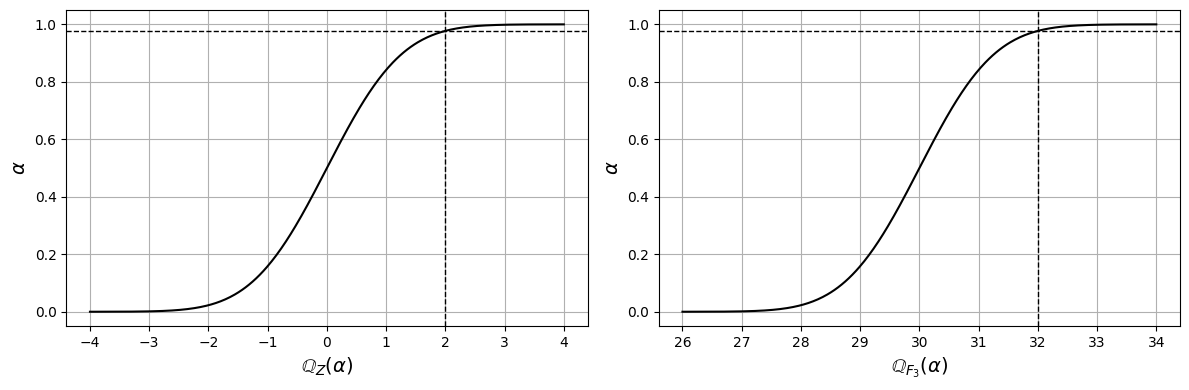

In [2]:
alpha = 0.977
z_alpha = norm.ppf(alpha)                  # Q_Z(alpha)
Q_F3 = mu_3 + sigma_3 * z_alpha            # Q_X(alpha) = mu + sigma z_alpha
print(f"z_alpha = {z_alpha:.3f},  Q_F3(alpha) = {Q_F3:.3f}  (direct: {norm.ppf(alpha, mu_3, sigma_3):.3f})")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
z = np.linspace(-4, 4, 400)
axs[0].plot(z, norm.cdf(z), 'k', linewidth=1.5)
axs[0].axhline(alpha, color='k', ls='--', lw=1)
axs[0].axvline(z_alpha, color='k', ls='--', lw=1)
axs[0].set_xlabel(r'$\mathbb{Q}_Z(\alpha)$', fontsize=14)
axs[0].set_ylabel(r'$\alpha$', fontsize=14)
x = np.linspace(mu_3 - 4*sigma_3, mu_3 + 4*sigma_3, 400)
axs[1].plot(x, norm.cdf(x, mu_3, sigma_3), 'k', linewidth=1.5)
axs[1].axhline(alpha, color='k', ls='--', lw=1)
axs[1].axvline(Q_F3, color='k', ls='--', lw=1)
axs[1].set_xlabel(r'$\mathbb{Q}_{F_3}(\alpha)$', fontsize=14)
axs[1].set_ylabel(r'$\alpha$', fontsize=14)
for ax in axs:
    ax.grid(True)
plt.tight_layout()
plt.show()

## 90% confidence region

$\mathbb{P}(\mu-z_{\alpha/2}\sigma\leq X\leq \mu+z_{\alpha/2}\sigma)=1-\alpha$ with
$z_{\alpha/2}=\mathbb{Q}_Z(1-\alpha/2)$; for 90% probability, $\alpha=0.1$.

z_alpha/2 = 1.645;  F3 in [28.36, 31.64] with 90% probability


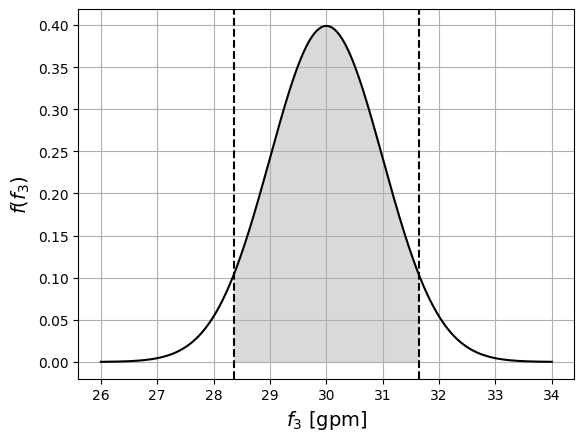

In [3]:
alpha = 0.10
z_alpha_2 = norm.ppf(1 - alpha/2)
lower, upper = mu_3 - z_alpha_2 * sigma_3, mu_3 + z_alpha_2 * sigma_3
print(f"z_alpha/2 = {z_alpha_2:.3f};  F3 in [{lower:.2f}, {upper:.2f}] with {100*(1-alpha):.0f}% probability")

plt.plot(x, norm.pdf(x, mu_3, sigma_3), 'black', linewidth=1.5)
plt.axvline(lower, color='k', ls='--')
plt.axvline(upper, color='k', ls='--')
plt.fill_between(x, norm.pdf(x, mu_3, sigma_3), where=(x >= lower) & (x <= upper), color='0.85')
plt.xlabel('$f_3$ [gpm]', fontsize=14)
plt.ylabel('$f(f_3)$', fontsize=14)
plt.grid(True)
plt.show()